In [1]:
import pandas as pd

In [2]:
# filepath_or_buffer
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"

In [3]:
df = pd.read_csv("./data/titanic.csv") # filepath

In [4]:
df = pd.read_csv(url) # buffer

In [5]:
df.tail(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
df.shape

(891, 12)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# Validar nulos en numéricos
df.count(axis = 0, numeric_only = True) < df.shape[0]

PassengerId    False
Survived       False
Pclass         False
Age             True
SibSp          False
Parch          False
Fare           False
dtype: bool

In [10]:
# Porcentaje de filas nulas
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

Age         19.865320
Cabin       77.104377
Embarked     0.224467
dtype: float64

In [11]:
# Opción 1: ELIMINAR - Una presencia alta de nulos usualmente > 15% se elimina *
del df["Cabin"]
# Opción 2: La falta de información es información (Crear valor sintético)
#df["Cabin"] = df["Cabin"].fillna("Unknow")

<Axes: >

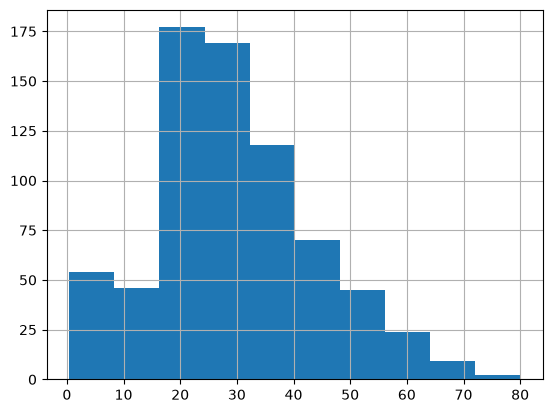

In [12]:
df["Age"].hist()

In [13]:
# Imputación
df["Age"] = df["Age"].fillna(df["Age"].median()).astype(int)

In [14]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26,0,0,111369,30.0000,C


In [15]:
# Porcentaje de filas nulas
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

Embarked    0.224467
dtype: float64

In [16]:
# Imputación con moda para categorias
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode().iloc[0])

<Axes: xlabel='PassengerId'>

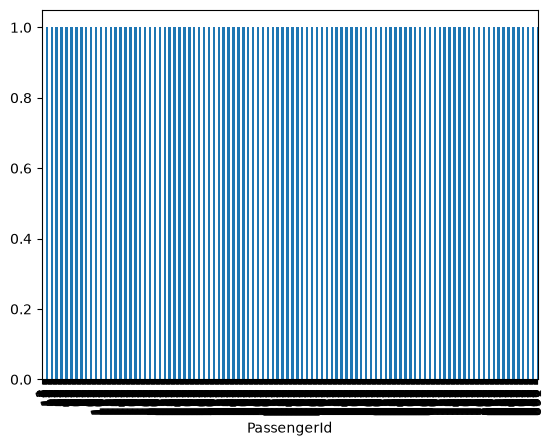

In [17]:
df["PassengerId"].value_counts().plot.bar()

In [18]:
# Eliminamos todo lo que se distribuye de forma uniforme
del df["PassengerId"]
del df["Name"]
del df["Ticket"]

In [19]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22,1,0,7.2500,S
1,1,1,female,38,1,0,71.2833,C
2,1,3,female,26,0,0,7.9250,S
3,1,1,female,35,1,0,53.1000,S
4,0,3,male,35,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27,0,0,13.0000,S
887,1,1,female,19,0,0,30.0000,S
888,0,3,female,28,1,2,23.4500,S
889,1,1,male,26,0,0,30.0000,C


In [20]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [21]:
df["Embarked"].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [22]:
df[["Pclass"]].groupby("Pclass").count()

""
Pclass
1
2
3


In [23]:
clases = []
for i in df["Pclass"]:
    clases.append(i)
set(clases)

{1, 2, 3}

In [24]:
categorical_columns = ["Pclass", "Sex", "Embarked"]
for column in categorical_columns:
    dummies = pd.get_dummies(df[column], prefix=column).astype(int)
    df = pd.concat([df, dummies], axis=1) # Por columnas (Biyección)
    del df[column]

In [38]:
df["Family_size"] = df["SibSp"] + df["Parch"] + 1

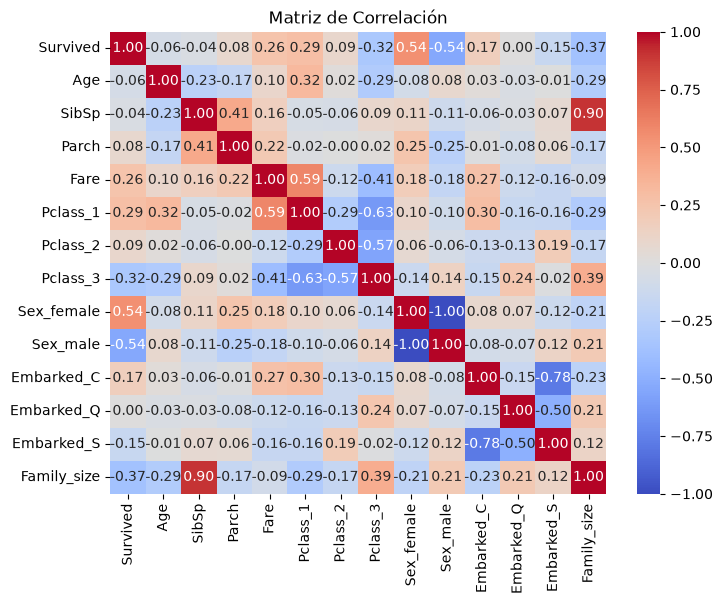

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    df.corr(),
    annot=True,  # Muestra los valores dentro de cada celda
    fmt=".2f",  # Define el formato numérico (2 decimales)
    cmap="coolwarm",  # Paleta de colores
    vmin=-1,
    vmax=1,  # Fija la escala entre -1 y 1
)
plt.title("Matriz de Correlación")
plt.show()

In [43]:
df.describe()

,Survived,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Family_size
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,29.345679,0.523008,0.381594,32.204208,0.242424,0.206510,0.551066,0.352413,0.647587,0.188552,0.086420,0.725028,1.904602
std,0.486592,13.028212,1.102743,0.806057,49.693429,0.428790,0.405028,0.497665,0.477990,0.477990,0.391372,0.281141,0.446751,1.613459
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,28.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
75%,1.000000,35.000000,1.000000,0.000000,31.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,2.000000
max,1.000000,80.000000,8.000000,6.000000,512.329200,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,11.000000


In [45]:
# MinMax Scaler
temp = (df["Age"] - df["Age"].min(axis=0)) / (df["Age"].max(axis=0) - df["Age"].min(axis=0))
temp.describe()

count    891.000000
mean       0.366821
std        0.162853
min        0.000000
25%        0.275000
50%        0.350000
75%        0.437500
max        1.000000
Name: Age, dtype: float64

In [46]:
# MinMax Scaler
numerical_values = ["Age", "SibSp", "Parch", "Fare", "Family_size"]
for column in numerical_values:
    df[column] = (
        (df[column] - df[column].min(axis=0))
        / (df[column].max(axis=0)
        - df[column].min(axis=0))
    )

In [47]:
df

,Survived,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Family_size
0,0,0.2750,0.125,0.000000,0.014151,0,0,1,0,1,0,0,1,0.1
1,1,0.4750,0.125,0.000000,0.139136,1,0,0,1,0,1,0,0,0.1
2,1,0.3250,0.000,0.000000,0.015469,0,0,1,1,0,0,0,1,0.0
3,1,0.4375,0.125,0.000000,0.103644,1,0,0,1,0,0,0,1,0.1
4,0,0.4375,0.000,0.000000,0.015713,0,0,1,0,1,0,0,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,0.3375,0.000,0.000000,0.025374,0,1,0,0,1,0,0,1,0.0
887,1,0.2375,0.000,0.000000,0.058556,1,0,0,1,0,0,0,1,0.0
888,0,0.3500,0.125,0.333333,0.045771,0,0,1,1,0,0,0,1,0.3
889,1,0.3250,0.000,0.000000,0.058556,1,0,0,0,1,1,0,0,0.0


In [49]:
X = df.drop("Survived", axis = 1) # Devuelve un dataframe sin la columna
Y = df["Survived"]

In [50]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(X)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [57]:
X_pca = pca.transform(X)

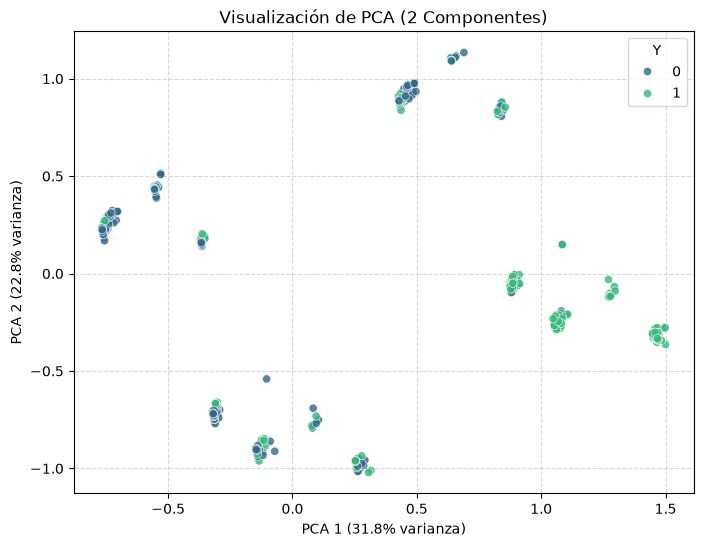

In [58]:
df_pca = pd.DataFrame(X_pca, columns=["PCA1", "PCA2"])
df_pca["Y"] = Y

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca,
    x="PCA1",
    y="PCA2",
    hue="Y",
    palette="viridis",
    alpha=0.8,
)

var1 = pca.explained_variance_ratio_[0] * 100
var2 = pca.explained_variance_ratio_[1] * 100
plt.xlabel(f"PCA 1 ({var1:.1f}% varianza)")
plt.ylabel(f"PCA 2 ({var2:.1f}% varianza)")

plt.title("Visualización de PCA (2 Componentes)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()